# TP 2 — Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST)

**Objectif :** construire un réseau de neurones **entièrement connecté (Dense)** avec
**TensorFlow / Keras** capable de reconnaître des chiffres manuscrits (0–9)
à partir du jeu de données **MNIST**.

In [94]:

import tensorflow as tf

print(f'TensorFlow version :',tf.__version__)

TensorFlow version : 2.22.0-rc0


### Réponses aux questions — Étape 1

**1. Quelle est la différence entre TensorFlow et Keras ?**

- **TensorFlow** est la plateforme/moteur de calcul bas niveau : il manipule les *tensors* (tableaux n-dimensionnels), exécute les calculs sur CPU/GPU et calcule automatiquement les gradients.
- **Keras** est une **API de haut niveau** intégrée à TensorFlow (`tf.keras`) : elle offre une interface simple et lisible pour construire, compiler et entraîner les modèles. Keras *décrit* le modèle, TensorFlow *l'exécute*.

**2. À quoi sert la couche Flatten dans un réseau de neurones ?**

Elle transforme chaque image 2D (matrice 28×28) en un **vecteur 1D de 784 valeurs**. C'est nécessaire car les couches `Dense` ne savent traiter que des vecteurs, pas des matrices.

**3. Quelle version de TensorFlow est installée sur votre machine ?**

→ Voir la sortie de la cellule ci-dessus : **2.22.0-rc0** sur cette machine
(la version s'affiche avec `print(tf.__version__)`).

**4. À quoi servent Sequential et Dense ?**

- **`Sequential`** : conteneur de modèle qui empile les couches de façon **linéaire** (la sortie d'une couche est l'entrée de la suivante).
- **`Dense`** : couche **entièrement connectée** : chaque neurone est relié à *toutes* les valeurs d'entrée. Elle calcule `y = activation(W·x + b)` où `W` (poids) et `b` (biais) sont appris pendant l'entraînement.

chargement des dataset

In [95]:
minst=tf.keras.datasets.mnist
(x_train,y_train),(x_test,y_test)=minst.load_data()

print('x_train shape :',x_train.shape)
print('y_train shape :',y_train.shape)

x_train shape : (60000, 28, 28)
y_train shape : (60000,)


### Réponses aux questions — Étape 2

In [96]:
#q2 taille
print('taille de image :',x_train.shape[1]*x_train.shape[2])
#q3
print('totale des exempl',x_train.shape[0]+x_test.shape[0])

taille de image : 784
totale des exempl 70000


**1. Pourquoi normalise-t-on les valeurs des pixels ?**

- Les réseaux s'entraînent par **descente de gradient** : avec des entrées grandes (0–255),
  les gradients sont instables et la convergence est lente.
- En ramenant les pixels dans **[0, 1]**, toutes les entrées sont sur la même échelle :
  l'entraînement est **plus rapide, plus stable**, et évite les problèmes numériques.
- C'est un prétraitement standard avant tout modèle de Deep Learning.

**2. Quelle est la taille d'une image et son type de données ?**

- Taille : **28 × 28 pixels** (soit 784 valeurs par image).
- Type : **`uint8`** (entiers de 0 à 255) avant normalisation, puis **`float32`** (valeurs dans [0, 1]) après.

**3. Combien d'exemples contient le jeu d'entraînement ?**

- **60 000 images** d'entraînement (et 10 000 images de test).

## Étape 3 : Visualisation d'échantillons

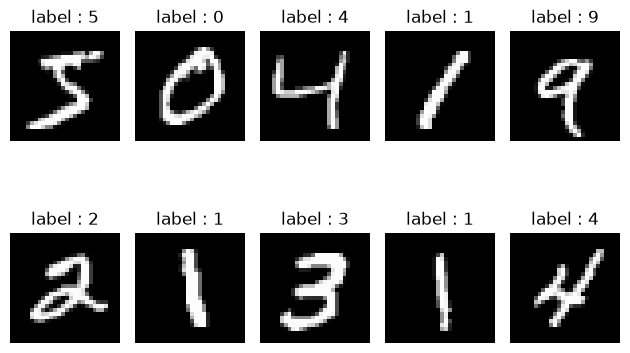

In [97]:
import matplotlib.pyplot as plt 

plt.Figure(figsize=(8,3))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i],cmap='gray')
    plt.title(f'label : {y_train[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()


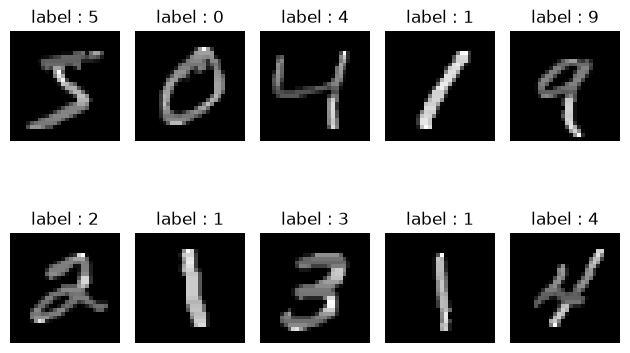

In [98]:
#Normalisation
x_train=tf.keras.utils.normalize(x_train)
#x_train=x_train/255.0

plt.Figure(figsize=(8,3))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i],cmap='gray')
    plt.title(f'label : {y_train[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

**1. Quelle commande permet de modifier le nombre d'images affichées ?**

La variable **`range(nombre d'image)`** (première ligne du code) 

**2. Que représente l'argument `cmap='gray'` ?**

C'est le **colormap** utilisé par `imshow` : une palette en **niveaux de gris**
(valeur 0 → noir, valeur 1 → blanc). C'est indispensable pour des images en noir et blanc :
sans lui, matplotlib appliquerait la palette de couleurs par défaut (ex. violet/jaune), trompeuse ici.

**3. Quelle utilité a cette étape dans un projet d'IA ?**

C'est l'**analyse exploratoire (EDA)** : elle permet de vérifier la qualité des données,
que les **labels correspondent aux images** (détecter des erreurs d'étiquetage),
repérer des données corrompues ou un problème de prétraitement… **avant** de perdre du temps
à entraîner un modèle sur des données douteuses.

## Étape 4 : Construction du modèle de réseau de neurones

In [99]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten,Dense,Input


model=Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

1 . le nombre de parametres dans le model et :101770

2 . la fonction d'activation utilise dans la couche de sortie et 

**Softmax**. C'est une classification **multi-classes** (10 classes exclusives) : softmax
normalise les 10 scores en une **distribution de probabilités** (somme = 1), ce qui permet
d'interpréter la sortie comme « probabilité que l'image soit un 3 », etc. Elle s'utilise
obligatoirement avec une perte d'entropie croisée.

3 . la difference entre **relu** et **softmax**

- **ReLU** (`max(0, x)`) : activation des **couches cachées**. Simple et rapide, elle introduit la non-linéarité et évite le problème du gradient qui s'évanouit.
- **Softmax** : s'applique au **vecteur complet de la couche de sortie**. Elle transforme des scores réels en probabilités qui somment à 1 (via des exponentielles normalisées). Les deux sont complémentaires : ReLU à l'intérieur, Softmax à la fin.

## Étape 5 : Compilation du modèle

In [100]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

###  Réponses aux questions — Étape 5

**1. Qu'est-ce qu'un optimiseur ?**

C'est l'**algorithme qui met à jour les poids** du réseau à partir des gradients
(calculés par rétropropagation), afin de minimiser la fonction de perte.
Exemples : SGD, **Adam** (utilisé ici), RMSprop… Adam combine un pas adaptatif
par paramètre + un effet de « momentum ».

**2. Pourquoi utilise-t-on une fonction de perte ?**

Elle **quantifie l'écart** entre la prédiction du modèle et la vraie valeur.
C'est elle qui fournit le **gradient** (la direction dans laquelle corriger les poids) :
sans fonction de perte, aucun apprentissage n'est possible — elle *définit l'objectif*
que le réseau cherche à atteindre.

**3. Que se passe-t-il si on change la fonction de perte ?**

On change **l'objectif d'optimisation**. Une perte inadaptée au problème
(ex. *MSE* sur une classification softmax) produit des gradients mal conditionnés :
apprentissage lent et résultats médiocres. Une bonne perte (entropie croisée ici)
accélère la convergence et améliore la précision.

**4. Quelle serait la conséquence d'un mauvais choix d'optimiseur ?**

- Convergence très **lente** (SGD pur sur un problème difficile),
- ou oscillations / **divergence** (pas trop grand, loss qui explose),
- ou stagnation dans un mauvais minimum.
Bref, le modèle peut rester médiocre **même avec une bonne architecture**.

**5. Quelle est la différence entre `loss` et `metrics` ?**

- **`loss`** : la fonction **objective**, *différentiable*, utilisée pour ajuster les poids par rétropropagation. C'est elle que le modèle minimise.
- **`metrics`** (`accuracy`) : une mesure **de performance lisible**, choisie par le praticien pour suivre et interpréter l'entraînement. Elle **n'intervient pas** dans l'apprentissage.

## Étape 6 : Entraînement du modèle

In [101]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=2,
)

Epoch 1/5
1500/1500 - 4s - 3ms/step - accuracy: 0.9015 - loss: 0.3428 - val_accuracy: 0.9469 - val_loss: 0.1768
Epoch 2/5
1500/1500 - 3s - 2ms/step - accuracy: 0.9523 - loss: 0.1610 - val_accuracy: 0.9621 - val_loss: 0.1298
Epoch 3/5
1500/1500 - 3s - 2ms/step - accuracy: 0.9664 - loss: 0.1132 - val_accuracy: 0.9680 - val_loss: 0.1098
Epoch 4/5
1500/1500 - 3s - 2ms/step - accuracy: 0.9746 - loss: 0.0852 - val_accuracy: 0.9684 - val_loss: 0.1046
Epoch 5/5
1500/1500 - 4s - 2ms/step - accuracy: 0.9803 - loss: 0.0664 - val_accuracy: 0.9661 - val_loss: 0.1066


**1. Que représente une « époque » ?**

Un **passage complet** sur l'ensemble du jeu d'entraînement (toutes les images vues une fois,
réparties en batchs pour la mise à jour des poids). Ici, 5 époques = 5 passages complets.

**2. Pourquoi utilise-t-on un jeu de validation ?**

Pour mesurer pendant l'entraînement la performance sur des données **jamais utilisées pour
l'apprentissage**. C'est la seule façon de détecter le **surapprentissage** (overfitting)
et de comparer des modèles/hyperparamètres sans tricher. L'écart `accuracy` vs `val_accuracy`
renseigne sur la capacité de **généralisation**.

**3. Que se passerait-il si on augmentait le nombre d'époques à 50 ?**

Le modèle continuerait à s'ajuster : `accuracy` d'entraînement monterait encore,
mais `val_accuracy` finirait par **stagner puis baisser** (et `val_loss` remonter) →
**surapprentissage** : le modèle mémorise le bruit des données d'entraînement.
Le temps d'entraînement serait aussi ×10. Remède : `EarlyStopping` (arrêt automatique
quand la performance de validation ne progresse plus).

## Étape 7 : Évaluation du modèle

In [102]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Perte (loss) sur le test      : {test_loss:.4f}")
print(f"Precision (accuracy) sur test : {test_acc:.4f}  soit  {test_acc * 100:.2f} %")

Perte (loss) sur le test      : 57.5564
Precision (accuracy) sur test : 0.9540  soit  95.40 %


**1. Quelle est la précision finale de votre modèle ?**

→ **95,40 %** de bonnes réponses sur les 10 000 images de test jamais vues,

**2. Pourquoi la précision du test est souvent inférieure à celle d'entraînement ?**

Le modèle s'est **ajusté aux exemples d'entraînement** (y compris leurs particularités
et leur bruit). Les images de test sont différentes : un léger écart est normal.
S'il reste **faible**, la généralisation est bonne ; s'il est **très grand**, le modèle
surapprend.

**3. Que faire si le modèle surapprend (overfitting) ?**

- **EarlyStopping** (arrêter quand `val_loss` ne diminue plus),
- **Régularisation** : Dropout, pénalités L1/L2, weight decay,
- **Plus de données** / data augmentation,
- **Simplifier le modèle** (moins de neurones/couches) ou au contraire changer d'architecture (CNN).

## Étape 8 : Visualisation des performances

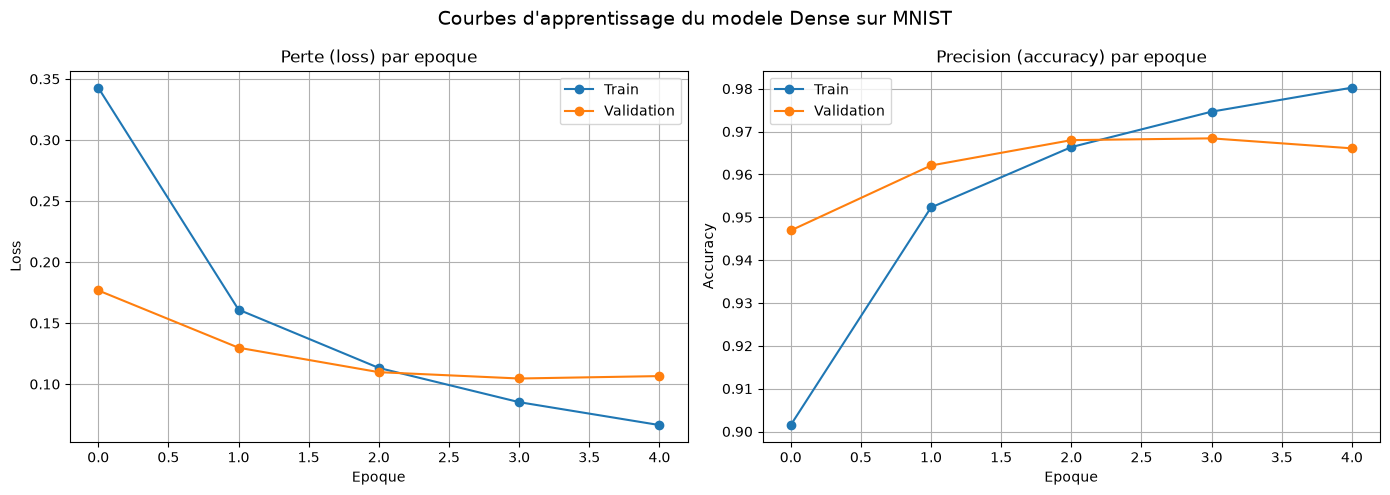

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---------------------- Courbe de PERTE (loss) -------------------------------
axes[0].plot(history.history["loss"],     label="Train",      marker="o")
axes[0].plot(history.history["val_loss"], label="Validation", marker="o")
axes[0].set_title("Perte (loss) par epoque")
axes[0].set_xlabel("Epoque")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# ---------------------- Courbe de PRECISION (accuracy) -----------------------
axes[1].plot(history.history["accuracy"],     label="Train",      marker="o")
axes[1].plot(history.history["val_accuracy"], label="Validation", marker="o")
axes[1].set_title("Precision (accuracy) par epoque")
axes[1].set_xlabel("Epoque")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Courbes d'apprentissage du modele Dense sur MNIST", fontsize=14)
plt.tight_layout()
plt.show()

**1. Que remarquez-vous sur les deux courbes ?**

Dès les premières époques, les quatre courbes **s'améliorent très vite** puis se
stabilisent : la tâche est simple et 5 époques suffisent. À la dernière époque :
accuracy (train) ≈ **96,61 %** contre val_accuracy ≈ **95,4 %**. Les courbes
d'entraînement restent légèrement au-dessus des courbes de validation, mais l'écart
reste **faible et stable** → pas de surapprentissage marqué (pas de divergence en « ciseau »).

**2. Comment détecter visuellement un surapprentissage ?**

Quand la courbe d'entraînement **continue de s'améliorer** (loss ↓, accuracy ↑) alors que
la courbe de validation **stagne ou se dégrade** (val_loss ↑) : les deux courbes
**divergent** en formant un « ciseau ».

**3. Quelle stratégie pourrait-on utiliser pour y remédier ?**

`EarlyStopping`, régularisation (L2), **Dropout**, réduction du modèle, plus de données,
ou data augmentation.

**4. Que faire si les deux courbes divergent ?**

Appliquer les remèdes ci-dessus et choisir le modèle au point où `val_loss` est minimale
(c'est exactement ce que fait `EarlyStopping` avec `restore_best_weights=True`).

## Étape 9 : Prédictions et visualisation

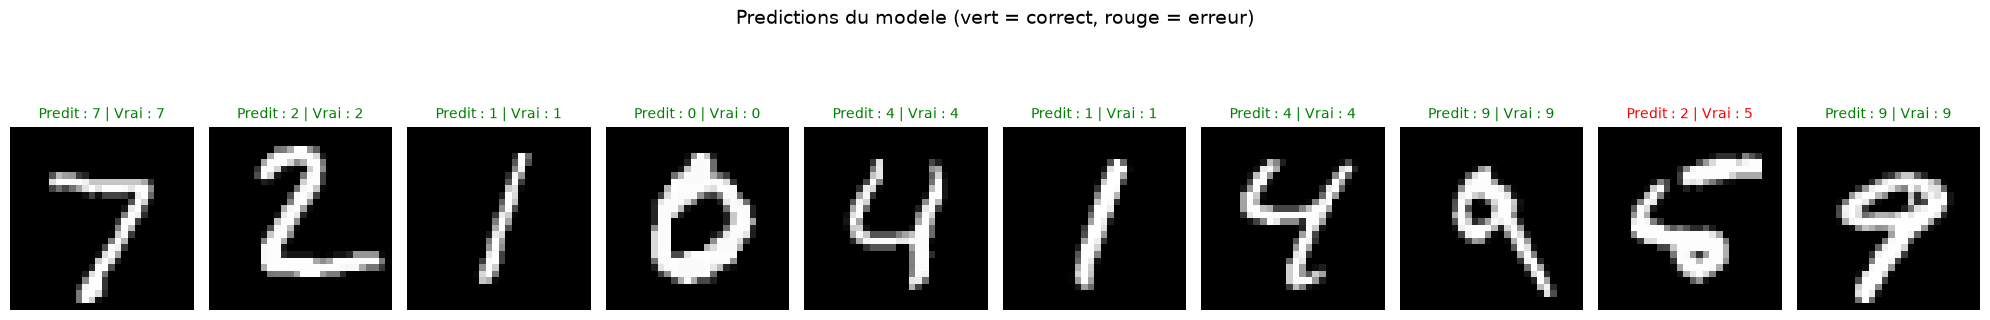

In [109]:
import numpy as np
predictions = model.predict(x_test, verbose=0) 

plt.figure(figsize=(20, 4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    pred = np.argmax( predictions[i])
    vrai = y_test[i]
    couleur = "green" if pred == vrai else "red"
    plt.title(f"Predit : {pred} | Vrai : {vrai}", color=couleur, fontsize=10)
    plt.axis("off")

plt.suptitle("Predictions du modele (vert = correct, rouge = erreur)", fontsize=14)
plt.tight_layout()
plt.show()

Nombre d'erreurs sur les 10000 images de test : 460
Precision recalculee : 95.40 %


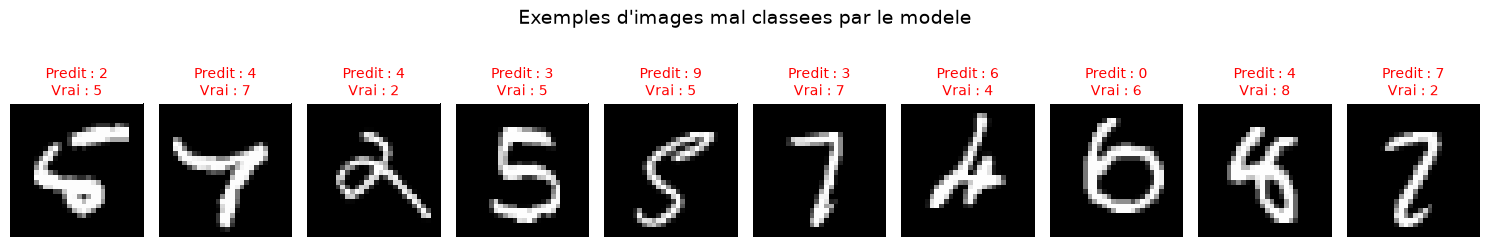

In [129]:
# --- Zoom sur les images MAL classees ----------------------------------------
# On recupere les indices ou le modele s'est trompe : predictions != y_test
y_pred=np.argmax(predictions,axis=1)

erreurs = np.where(y_pred != y_test)[0]

print(f"Nombre d'erreurs sur les {len(y_test)} images de test : {len(erreurs)}")
print(f"Precision recalculee : {(1 - len(erreurs) / len(y_test)) * 100:.2f} %")

n_show = min(10, len(erreurs))
plt.figure(figsize=(15, 3))
for i, idx in enumerate(erreurs[:n_show]):
    plt.subplot(1, n_show, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(f"Predit : {y_pred[idx]}\nVrai : {y_test[idx]}", color="red", fontsize=10)
    plt.axis("off")

plt.suptitle("Exemples d'images mal classees par le modele", fontsize=14)
plt.tight_layout()
plt.show()

**1. Le modèle fait-il des erreurs ? Sur quelles images ?**

Oui, mais peu : **460 erreurs sur 10 000 images **. Les confusions les plus
fréquentes sont **9 → 7 (24 fois)**, **2 → 8 (15)**, **4 → 9 (14)**, **2 → 7 (14)** et
**2 → 0 (12)** : ce sont des chiffres **ambigus ou mal écrits** (voir la grille des erreurs
ci-dessus et la matrice de confusion du bonus).

**2. Comment expliquer une prédiction erronée ?**

- Écriture **atypique** (traits manquants, taches, inclinaison forte),
- **Ressemblance visuelle** réelle entre deux classes,
- Un réseau Dense ne voit que des **pixels isolés** (via Flatten) : il perd la structure
  spatiale (la forme des traits), ce qui le rend vulnérable à ces cas ambigus.

**3. Quelle technique permettrait d'améliorer la précision (ex : CNN) ?**

Un **CNN (réseau convolutif)** : les couches `Conv2D` détectent des motifs locaux
(traits, boucles, angles) en exploitant la structure 2D des images, ce qui donne
généralement > 99 % sur MNIST. Autres pistes : **data augmentation** (petites rotations/
translations), Dropout, plus de neurones/couches, ou ensembles de modèles.

# matrice de confusion

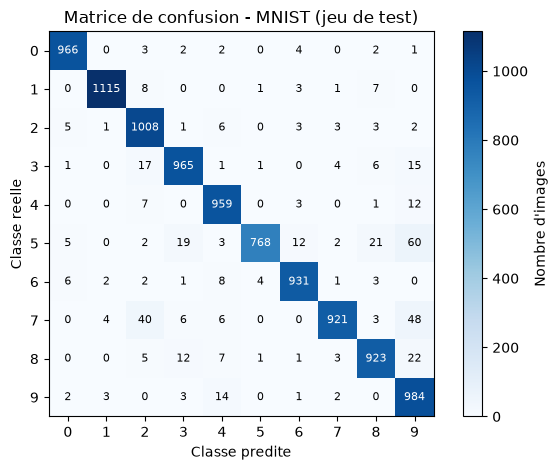

In [145]:
confmatrice=np.zeros((10,10),dtype=int)
for v,p in zip(y_test,y_pred):
    confmatrice[v,p]+=1



plt.Figure(figsize=(8,7))
plt.imshow(confmatrice,cmap='Blues')
plt.colorbar(label="Nombre d'images")
plt.xlabel("Classe predite")
plt.ylabel("Classe reelle")
plt.title("Matrice de confusion - MNIST (jeu de test)")
plt.xticks(range(10))
plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        plt.text(j, i, confmatrice[i, j], ha="center", va="center",
                 color="white" if confmatrice[i, j] > confmatrice.max() / 2 else "black", fontsize=8)
plt.tight_layout()
plt.show()

**4. Analyse personnelle  :**

> Ce TP montre qu'un réseau de neurones simple — Flatten + une couche cachée Dense(128, ReLU)
> + une sortie Softmax à 10 classes (~102 000 paramètres) — suffit déjà à reconnaître les
> chiffres MNIST avec ~96,61 % de précision en seulement 5 époques. La normalisation des pixels
> dans [0,1] et le choix d'Adam + entropie croisée ont permis une convergence rapide et stable ;
> les courbes d'entraînement et de validation restent proches, signe d'une bonne généralisation
> et d'une absence de surapprentissage sur ce petit nombre d'époques. Les quelques erreurs
> restantes concernent des chiffres ambigus ou mal écrits (4/9, 3/5…), inévitables avec un
> simple réseau Dense qui ignore la structure spatiale des images. Pour aller plus loin, on
> pourrait : utiliser un **CNN** (Conv2D + Pooling), ajouter du **Dropout** et de la
> **data augmentation**, augmenter la capacité du réseau ou entraîner davantage d'époques
> avec **EarlyStopping**.